#  Pantograph Contact Strip — Pipeline 2 étages (YOLO ROI + Segmentation)




In [15]:
# Si tu utilises PyTorch
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

# Si tu utilises TensorFlow
!pip install tensorflow[and-cuda]

# Utilitaires GPU
!pip install cupy-cuda13x

^C
Looking in indexes: https://download.pytorch.org/whl/cu121
  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.4.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.35.1-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.81.1-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached keras-3.14.1-py3-none-any.whl.metadata (6.3 kB)
  Using cached h5py-3.14.0-cp313-cp313-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-

ERROR: Cannot install tensorflow[and-cuda]==2.20.0 and tensorflow[and-cuda]==2.21.0 because these package versions have conflicting dependencies.
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.4.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.35.1-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.81.1-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached keras-3.14.1-py3-none-any.whl.metadata (6.3 kB)
  Using cached h5py-3.14.0-cp313-cp313-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.5.4-cp313-cp313-win_amd64.whl.metadata (9.2 kB)
  Using cach

ERROR: Cannot install tensorflow[and-cuda]==2.20.0 and tensorflow[and-cuda]==2.21.0 because these package versions have conflicting dependencies.
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


In [ ]:
# ============================================================
#  INSTALLATION
# ============================================================
# !pip install -q ultralytics pycocotools

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler
import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import torchvision.ops as ops
import json, os, cv2, random, re, copy, shutil, yaml, glob
import numpy as np
from PIL import Image
from pycocotools import mask as coco_mask
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Utilisation de :", device)

# ============================================================
#  CONFIGURATION — CORRIGÉE
# ============================================================
BASE_DIR = Path(r"mettre ta base de données ici")  # ✅ à modifier selon ton environnement

CFG = {
    # --- Sources --- NOMS CORRIGÉS (lot1 = images montées sur rame)
    "img_dir_lot1" : str(BASE_DIR / "Lot1" / "images"),                   # ✅ 288 images complètes
    "ann_lot1"     : str(BASE_DIR / "Lot1" / "instances_default.json"),   # ✅
    "img_dir_lot3" : str(BASE_DIR / "Lot3" / "augmented_images_final"),   # ✅ 2695 crops augmentés
    "ann_lot3"     : str(BASE_DIR / "Lot3" / "augmented_annotations_final.json"), # ✅

    # --- Sorties --- chemins absolus + slash forward
    "stats_dir"        : str(BASE_DIR / "stats"),
    "yolo_dataset_dir" : str(BASE_DIR / "yolo_pantograph"),
    "yolo_output_dir"  : str(BASE_DIR / "runs" / "detect" / "yolo_runs"),  # ✅ plus de backslash
    "hard_neg_dir"     : str(BASE_DIR / "hard_negatives_v4"),
    "roi_crops_dir"    : str(BASE_DIR / "roi_crops_v4"),
    "merged_ann"       : str(BASE_DIR / "merged_v4_annotations.json"),
    "seg_output_dir"   : str(BASE_DIR / "models_v4"),

    # --- YOLO --- mis à jour
    "yolo_model"       : "yolov8n.pt",   # ✅ small au lieu de nano
    "yolo_epochs"      : 150,            # ✅ augmenté
    "yolo_imgsz"       : 640,
    "yolo_batch"       : 8,              # ✅ réduit pour yolov8s
    "yolo_conf_thresh" : 0.4,
    "roi_margin_pct"   : 0.15,

    # --- Segmentation ---
    "batch_size"      : 4,
    "num_epochs"      : 40,
    "lr_from_scratch" : 0.005,
    "lr_finetune"     : 0.0002,
    "weight_decay"    : 0.0005,
    "patience"        : 10,
    "pretrained_ckpt" : None,
    "w_lot1"          : 1.0,
    "w_lot3"          : 2.5,
    "n_hard_neg"      : 150,
    "seed"            : 42,
    "device"          : "cuda" if torch.cuda.is_available() else "cpu",
}

random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])

for d in ["stats_dir", "yolo_dataset_dir", "yolo_output_dir", "hard_neg_dir",
          "roi_crops_dir", "seg_output_dir"]:
    Path(CFG[d]).mkdir(parents=True, exist_ok=True)

print(f"Device : {CFG['device']}")
print(f"Torch  : {torch.__version__}")
print(f"Config OK — {len(CFG)} paramètres chargés")
print(f"BASE_DIR : {BASE_DIR}")

Utilisation de : cuda
Device : cuda
Torch  : 2.11.0+cu128
Config OK — 29 paramètres chargés
BASE_DIR : C:\Users\oumaima.tayyarat\Documents\SegBande


In [ ]:
# ============================================================
#  VÉRIFICATION DES CHEMINS
# ============================================================
import os
from pathlib import Path


# Met les tiens 
# checks = {
#     "img_dir_lot1  (SegBande)"     : CFG["img_dir_lot1"],
#     "ann_lot1      (augmented)"    : CFG["ann_lot1"],
#     "img_dir_lot3  (Lot1/images)"  : CFG["img_dir_lot3"],
#     "ann_lot3      (instances)"    : CFG["ann_lot3"],
# }

print("=" * 60)
print("CHEMINS SOURCES")
print("=" * 60)
for label, path in checks.items():
    p = Path(path)
    exists = p.exists()
    if exists and p.is_dir():
        files = list(p.iterdir())
        imgs  = [f for f in files if f.suffix.lower() in [".jpg", ".jpeg", ".png"]]
        print(f"✅ {label}")
        print(f"   → {path}")
        print(f"   → {len(files)} fichiers total | {len(imgs)} images")
    elif exists and p.is_file():
        size = p.stat().st_size / 1024
        print(f"✅ {label}")
        print(f"   → {path}")
        print(f"   → fichier {size:.1f} KB")
    else:
        print(f"❌ {label}")
        print(f"   → {path}  ← INTROUVABLE")
        # Cherche le dossier parent pour aider
        parent = p.parent
        if parent.exists():
            contenu = [x.name for x in parent.iterdir()][:10]
            print(f"   → Parent '{parent}' existe, contient : {contenu}")
        else:
            print(f"   → Parent '{parent}' introuvable non plus")

print()
print("=" * 60)
print("CHEMINS SORTIE")
print("=" * 60)
for key in ["stats_dir", "yolo_dataset_dir", "hard_neg_dir", "roi_crops_dir", "seg_output_dir"]:
    p = Path(CFG[key])
    status = "✅ existe" if p.exists() else "📁 sera créé"
    print(f"{status}  {key:20s} → {CFG[key]}")

print()
print("=" * 60)
print("RÉPERTOIRE COURANT")
print("=" * 60)
cwd = Path.cwd()
print(f"→ {cwd}")
print(f"Contenu :")
for item in sorted(cwd.iterdir())[:20]:
    marker = "📁" if item.is_dir() else "📄"
    print(f"  {marker} {item.name}")

CHEMINS SOURCES
✅ img_dir_lot1  (SegBande)
   → C:\Users\oumaima.tayyarat\Documents\SegBande\Lot1\images
   → 288 fichiers total | 288 images
✅ ann_lot1      (augmented)
   → C:\Users\oumaima.tayyarat\Documents\SegBande\Lot1\instances_default.json
   → fichier 173.1 KB
✅ img_dir_lot3  (Lot1/images)
   → C:\Users\oumaima.tayyarat\Documents\SegBande\Lot3\augmented_images_final
   → 2695 fichiers total | 2695 images
✅ ann_lot3      (instances)
   → C:\Users\oumaima.tayyarat\Documents\SegBande\Lot3\augmented_annotations_final.json
   → fichier 5858.5 KB

CHEMINS SORTIE
✅ existe  stats_dir            → C:\Users\oumaima.tayyarat\Documents\SegBande\stats
✅ existe  yolo_dataset_dir     → C:\Users\oumaima.tayyarat\Documents\SegBande\yolo_pantograph
✅ existe  hard_neg_dir         → C:\Users\oumaima.tayyarat\Documents\SegBande\hard_negatives_v4
✅ existe  roi_crops_dir        → C:\Users\oumaima.tayyarat\Documents\SegBande\roi_crops_v4
✅ existe  seg_output_dir       → C:\Users\oumaima.tayyarat\Docu

In [ ]:
# ============================================================
#  UTILITAIRES COMMUNS
# ============================================================

def find_img_path(img_dir, file_name):
    for name in [file_name, file_name.replace('.jpg', '.JPG'),
                 file_name.replace('.jpeg', '.JPG'), file_name.replace('.png', '.PNG')]:
        p = Path(img_dir) / name
        if p.exists():
            return p
    return None

def load_coco_json(ann_file):
    with open(ann_file) as f:
        return json.load(f)

def decode_segmentation(ann, h, w):
    if isinstance(ann["segmentation"], list):
        mask = np.zeros((h, w), dtype=np.uint8)
        for seg in ann["segmentation"]:
            if len(seg) >= 6:
                pts = np.array(seg).reshape(-1, 2).astype(np.int32)
                cv2.fillPoly(mask, [pts], 1)
    elif isinstance(ann["segmentation"], dict):
        mask = coco_mask.decode(ann["segmentation"])
    else:
        mask = np.zeros((h, w), dtype=np.uint8)
    return mask

def load_all_coco(img_dirs, ann_files):
    """Fusionne plusieurs sources COCO (lot1 + lot3) en une structure unique."""
    merged_imgs, merged_anns, merged_cats = [], [], None
    img_id_offset, ann_id_offset = 0, 0
    source_map = {}   # nouvel img_id -> (img_dir, original file_name)

    for img_dir, ann_file in zip(img_dirs, ann_files):
        if not Path(ann_file).exists():
            print(f"  Annotation introuvable, ignorée : {ann_file}")
            continue
        data = load_coco_json(ann_file)
        if merged_cats is None:
            merged_cats = data["categories"]

        id_map = {}
        for img in data["images"]:
            new_id = img["id"] + img_id_offset
            id_map[img["id"]] = new_id
            new_img = dict(img)
            new_img["id"] = new_id
            merged_imgs.append(new_img)
            source_map[new_id] = img_dir

        for ann in data["annotations"]:
            new_ann = dict(ann)
            new_ann["id"] = ann["id"] + ann_id_offset
            new_ann["image_id"] = id_map[ann["image_id"]]
            merged_anns.append(new_ann)

        img_id_offset = max([im['id'] for im in merged_imgs], default=0) + 1
        ann_id_offset = max([a['id'] for a in merged_anns], default=0) + 1

    return {"images": merged_imgs, "annotations": merged_anns,
            "categories": merged_cats}, source_map

print(" Utilitaires chargés")


✅ Utilitaires chargés


## Étape 1 — Mesurer les vraies géométries de tes bandes annotées

**Avant toute config de filtre, on mesure.** Ceci remplace les valeurs devinées (`min_aspect_ratio=2.5`,
`min_area=4000-300000`) par des seuils calculés sur tes annotations réelles (lot1 + lot3).


📊 STATISTIQUES SUR 9464 ANNOTATIONS RÉELLES

Aspect ratio          min=1.00  p5=1.10  median=2.59  p95=10.54  max=35.97
Aire (px²)            min=258  p5=3443  median=26134  p95=165187  max=2073600
Aire relative (%)     min=0.06%  median=6.18%  max=100.00%

🎯 SEUILS CALIBRÉS (remplacent les valeurs devinées de la V3) :
   min_aspect_ratio     = 0.82
   min_area             = 560.62
   max_area             = 1652737.13


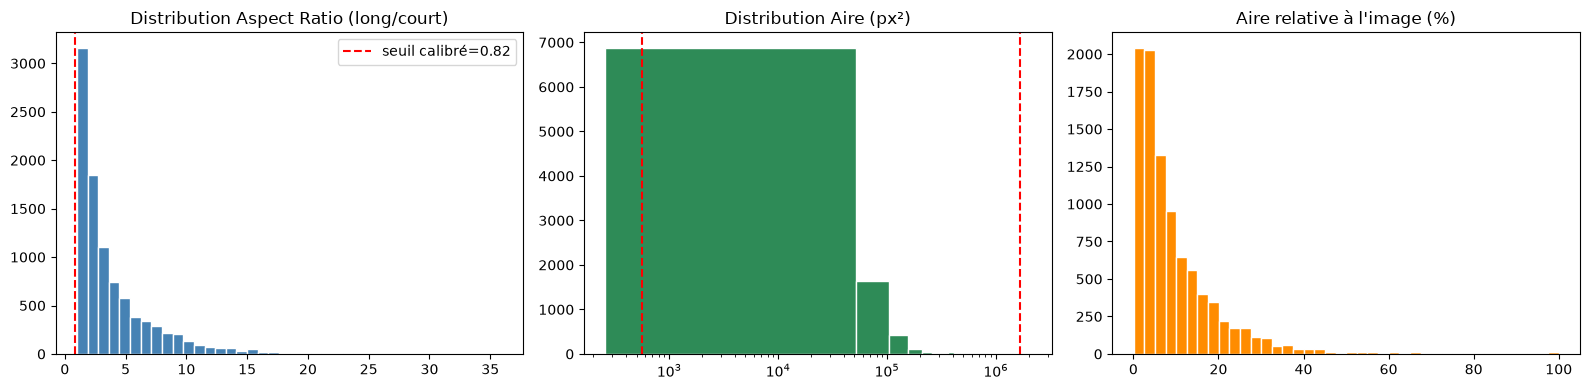


⚠️  Si min_aspect_ratio calibré < 2.0, c'est le signe que beaucoup de tes
   annotations sont déjà des boîtes peu allongées (vue de face/partielle).
   Vérifie aussi visuellement quelques exemples ci-dessous.


In [9]:
# ============================================================
#  ÉTAPE 1 — STATISTIQUES RÉELLES DES ANNOTATIONS
# ============================================================

merged_data, source_map = load_all_coco(
    img_dirs  = [CFG["img_dir_lot1"], CFG["img_dir_lot3"]],
    ann_files = [CFG["ann_lot1"], CFG["ann_lot3"]],
)

img_info_map = {img["id"]: img for img in merged_data["images"]}

aspect_ratios, areas, widths, heights, rel_areas = [], [], [], [], []

for ann in merged_data["annotations"]:
    x, y, bw, bh = ann["bbox"]
    if bw <= 0 or bh <= 0:
        continue
    img_info = img_info_map.get(ann["image_id"])
    if img_info is None:
        continue

    long_side  = max(bw, bh)
    short_side = min(bw, bh) + 1e-6
    ar = long_side / short_side

    aspect_ratios.append(ar)
    areas.append(bw * bh)
    widths.append(bw)
    heights.append(bh)
    rel_areas.append((bw * bh) / (img_info["width"] * img_info["height"]))

aspect_ratios = np.array(aspect_ratios)
areas         = np.array(areas)
rel_areas     = np.array(rel_areas)

print(f"📊 STATISTIQUES SUR {len(aspect_ratios)} ANNOTATIONS RÉELLES\n")
print(f"{'Aspect ratio':20s}  min={aspect_ratios.min():.2f}  "
      f"p5={np.percentile(aspect_ratios,5):.2f}  "
      f"median={np.median(aspect_ratios):.2f}  "
      f"p95={np.percentile(aspect_ratios,95):.2f}  max={aspect_ratios.max():.2f}")
print(f"{'Aire (px²)':20s}  min={areas.min():.0f}  "
      f"p5={np.percentile(areas,5):.0f}  "
      f"median={np.median(areas):.0f}  "
      f"p95={np.percentile(areas,95):.0f}  max={areas.max():.0f}")
print(f"{'Aire relative (%)':20s}  min={rel_areas.min()*100:.2f}%  "
      f"median={np.median(rel_areas)*100:.2f}%  max={rel_areas.max()*100:.2f}%")

# ── Seuils calibrés (percentiles 1 et 99 pour garder une marge) ─────────────
CALIBRATED = {
    "min_aspect_ratio" : float(np.percentile(aspect_ratios, 1)) * 0.8,   # marge de sécurité
    "min_area"          : float(np.percentile(areas, 1)) * 0.7,
    "max_area"          : float(np.percentile(areas, 99)) * 1.3,
}
print(f"\n🎯 SEUILS CALIBRÉS (remplacent les valeurs devinées de la V3) :")
for k, v in CALIBRATED.items():
    print(f"   {k:20s} = {v:.2f}")

CFG.update(CALIBRATED)

# ── Visualisation des distributions ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(aspect_ratios, bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(CALIBRATED["min_aspect_ratio"], color="red", linestyle="--",
                 label=f"seuil calibré={CALIBRATED['min_aspect_ratio']:.2f}")
axes[0].set_title("Distribution Aspect Ratio (long/court)")
axes[0].legend()

axes[1].hist(areas, bins=40, color="seagreen", edgecolor="white")
axes[1].axvline(CALIBRATED["min_area"], color="red", linestyle="--")
axes[1].axvline(CALIBRATED["max_area"], color="red", linestyle="--")
axes[1].set_title("Distribution Aire (px²)")
axes[1].set_xscale("log")

axes[2].hist(rel_areas * 100, bins=40, color="darkorange", edgecolor="white")
axes[2].set_title("Aire relative à l'image (%)")
plt.tight_layout()
plt.savefig(f"{CFG['stats_dir']}/geometry_stats.png", dpi=120)
plt.show()

print("\n⚠️  Si min_aspect_ratio calibré < 2.0, c'est le signe que beaucoup de tes")
print("   annotations sont déjà des boîtes peu allongées (vue de face/partielle).")
print("   Vérifie aussi visuellement quelques exemples ci-dessous.")


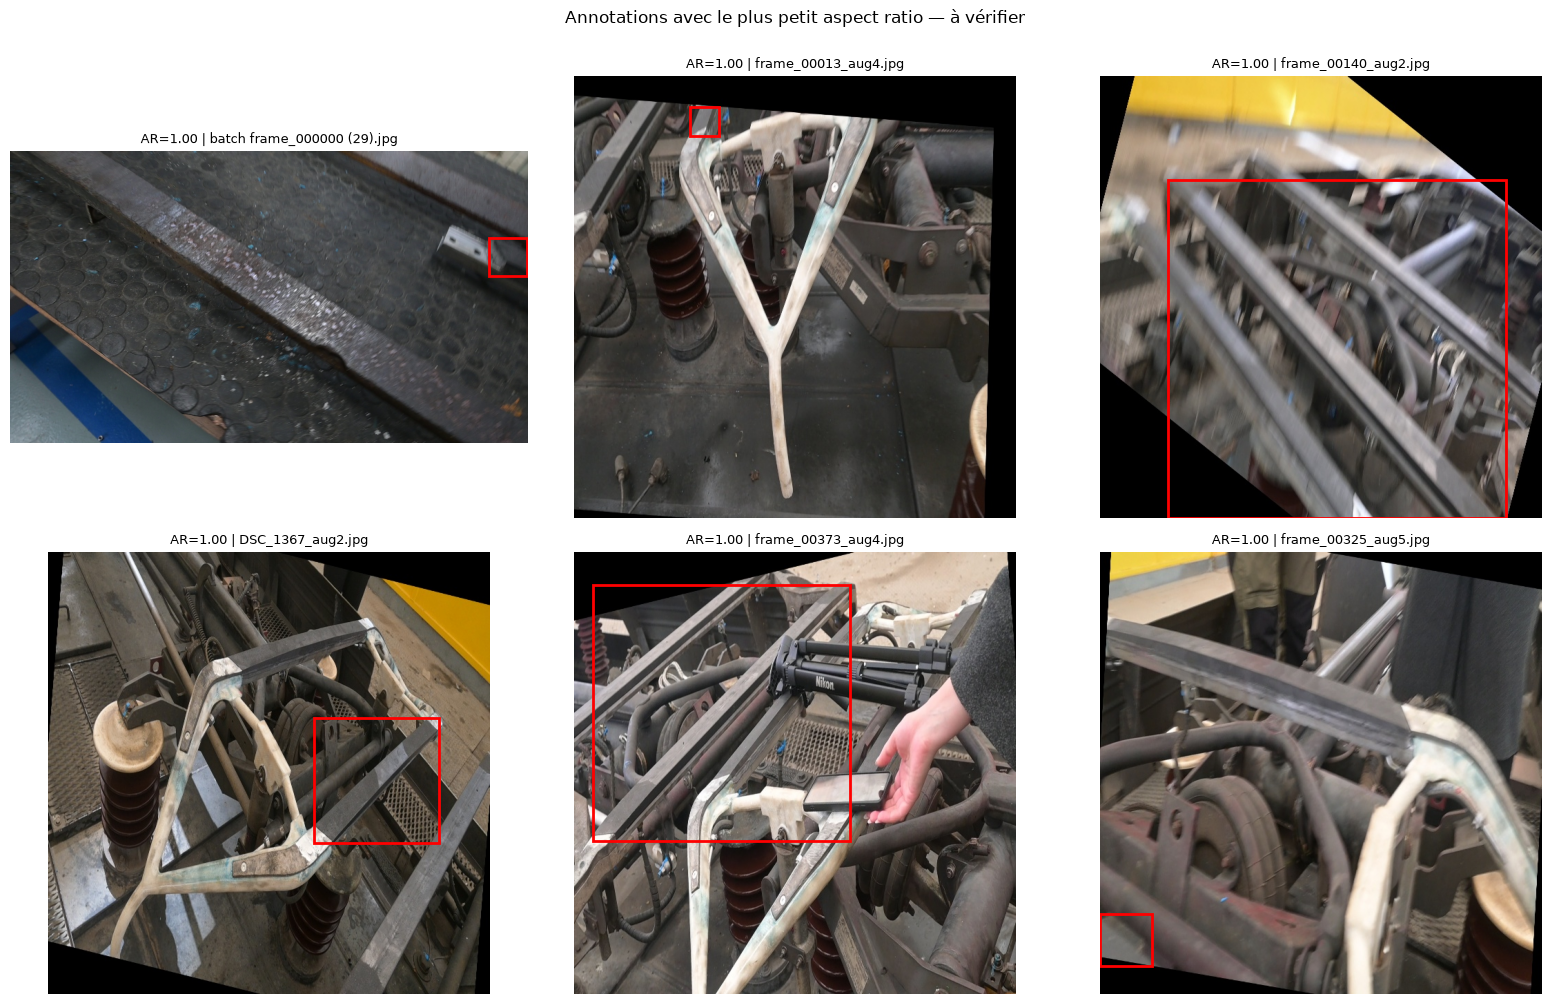

In [10]:
# ── Vérification visuelle : annotations avec le plus petit aspect ratio ─────
# Ça permet de voir si ce sont de vraies bandes vues d'un angle particulier
# ou des erreurs d'annotation à corriger.

ann_with_ar = []
for ann in merged_data["annotations"]:
    x, y, bw, bh = ann["bbox"]
    if bw <= 0 or bh <= 0:
        continue
    ar = max(bw, bh) / (min(bw, bh) + 1e-6)
    ann_with_ar.append((ar, ann))

ann_with_ar.sort(key=lambda t: t[0])
lowest_ar_anns = ann_with_ar[:6]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, (ar, ann) in zip(axes, lowest_ar_anns):
    img_info = img_info_map[ann["image_id"]]
    img_dir = source_map[ann["image_id"]]
    img_path = find_img_path(img_dir, img_info["file_name"])
    if img_path is None:
        ax.set_title("image introuvable")
        ax.axis("off")
        continue
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    x, y, bw, bh = ann["bbox"]
    ax.imshow(img)
    rect = mpatches.Rectangle((x, y), bw, bh, linewidth=2,
                               edgecolor="red", facecolor="none")
    ax.add_patch(rect)
    ax.set_title(f"AR={ar:.2f} | {img_info['file_name'][:30]}", fontsize=9)
    ax.axis("off")

plt.suptitle("Annotations avec le plus petit aspect ratio — à vérifier", y=1.0)
plt.tight_layout()
plt.show()


## Étape 2 — Préparation du dataset YOLO (détection ROI pantographe)

YOLO ne détecte pas chaque bande individuellement ici — il détecte **le pantographe entier comme un seul objet
macro**. Ça résout directement ton problème de "la bande peut changer de position/zone selon le casque" : peu
importe où le pantographe se trouve dans le champ de la caméra AR, YOLO le localise d'abord, puis on segmente
seulement à l'intérieur.

**Le ROI pantographe = la bounding box englobante de toutes les bandes annotées sur une image**, avec une marge.


In [22]:
# ============================================================
#  ÉTAPE 2 — CONVERSION COCO → YOLO (ROI pantographe = englobante des bandes)
# ============================================================



def build_pantograph_roi_dataset(merged_data, source_map, output_dir,
                                  margin_pct=0.15, val_ratio=0.2):
    """
    Pour chaque image annotée, calcule la bbox englobante de TOUTES les bandes
    présentes = ROI pantographe, avec une marge. Génère un dataset YOLO
    avec une seule classe 'pantograph_roi'.
    """
    output_dir = Path(output_dir)
    for split in ["train", "val"]:
        (output_dir / "images" / split).mkdir(parents=True, exist_ok=True)
        (output_dir / "labels" / split).mkdir(parents=True, exist_ok=True)

    img_anns = defaultdict(list)
    for ann in merged_data["annotations"]:
        img_anns[ann["image_id"]].append(ann)

    img_info_map = {img["id"]: img for img in merged_data["images"]}

    # Split par groupe (basename sans suffixe d'augmentation) pour éviter leakage
    groups = defaultdict(list)
    for img_id in img_anns.keys():
        info = img_info_map.get(img_id)
        if info is None:
            continue
        base = re.sub(r"_(aug|cp_v[0-9]?)\d+$", "", Path(info["file_name"]).stem)
        groups[base].append(img_id)

    group_keys = list(groups.keys())
    random.shuffle(group_keys)
    split_idx = int(len(group_keys) * (1 - val_ratio))
    train_groups, val_groups = group_keys[:split_idx], group_keys[split_idx:]

    stats = {"train": 0, "val": 0, "skipped": 0}

    for split, grp_keys in [("train", train_groups), ("val", val_groups)]:
        for g in grp_keys:
            for img_id in groups[g]:
                info = img_info_map[img_id]
                img_dir = source_map[img_id]
                img_path = find_img_path(img_dir, info["file_name"])
                if img_path is None:
                    stats["skipped"] += 1
                    continue

                anns = img_anns[img_id]
                xs1, ys1, xs2, ys2 = [], [], [], []
                for ann in anns:
                    x, y, bw, bh = ann["bbox"]
                    xs1.append(x); ys1.append(y)
                    xs2.append(x + bw); ys2.append(y + bh)

                x1, y1, x2, y2 = min(xs1), min(ys1), max(xs2), max(ys2)
                w_img, h_img = info["width"], info["height"]

                # Ajouter la marge
                roi_w, roi_h = x2 - x1, y2 - y1
                mx, my = roi_w * margin_pct, roi_h * margin_pct
                x1 = max(0, x1 - mx); y1 = max(0, y1 - my)
                x2 = min(w_img, x2 + mx); y2 = min(h_img, y2 + my)

                # Conversion YOLO (cx, cy, w, h normalisés)
                cx = (x1 + x2) / 2 / w_img
                cy = (y1 + y2) / 2 / h_img
                nw = (x2 - x1) / w_img
                nh = (y2 - y1) / h_img

                out_img_name = f"{img_id}_{Path(info['file_name']).stem}.jpg"
                out_img_path = output_dir / "images" / split / out_img_name
                out_lbl_path = output_dir / "labels" / split / (Path(out_img_name).stem + ".txt")

                img = cv2.imread(str(img_path))
                if img is None:
                    stats["skipped"] += 1
                    continue
                cv2.imwrite(str(out_img_path), img)

                with open(out_lbl_path, "w") as f:
                    f.write(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")

                stats[split] += 1

    # Fichier YAML de config YOLO
    yaml_content = {
        "path"  : str(output_dir),
        "train" : "images/train",
        "val"   : "images/val",
        "names" : {0: "pantograph_roi"},
    }
    yaml_path = output_dir / "dataset.yaml"
    with open(yaml_path, "w") as f:
        yaml.dump(yaml_content, f)

    print(f"✅ Dataset YOLO créé : {output_dir}")
    print(f"   Train : {stats['train']} | Val : {stats['val']} | Skipped : {stats['skipped']}")
    print(f"   Config : {yaml_path}")

    return str(yaml_path)


yolo_yaml_path = build_pantograph_roi_dataset(
    merged_data, source_map,
    output_dir = CFG["yolo_dataset_dir"],
    margin_pct = CFG["roi_margin_pct"],
)


✅ Dataset YOLO créé : C:\Users\oumaima.tayyarat\Documents\SegBande\yolo_pantograph
   Train : 2396 | Val : 586 | Skipped : 0
   Config : C:\Users\oumaima.tayyarat\Documents\SegBande\yolo_pantograph\dataset.yaml


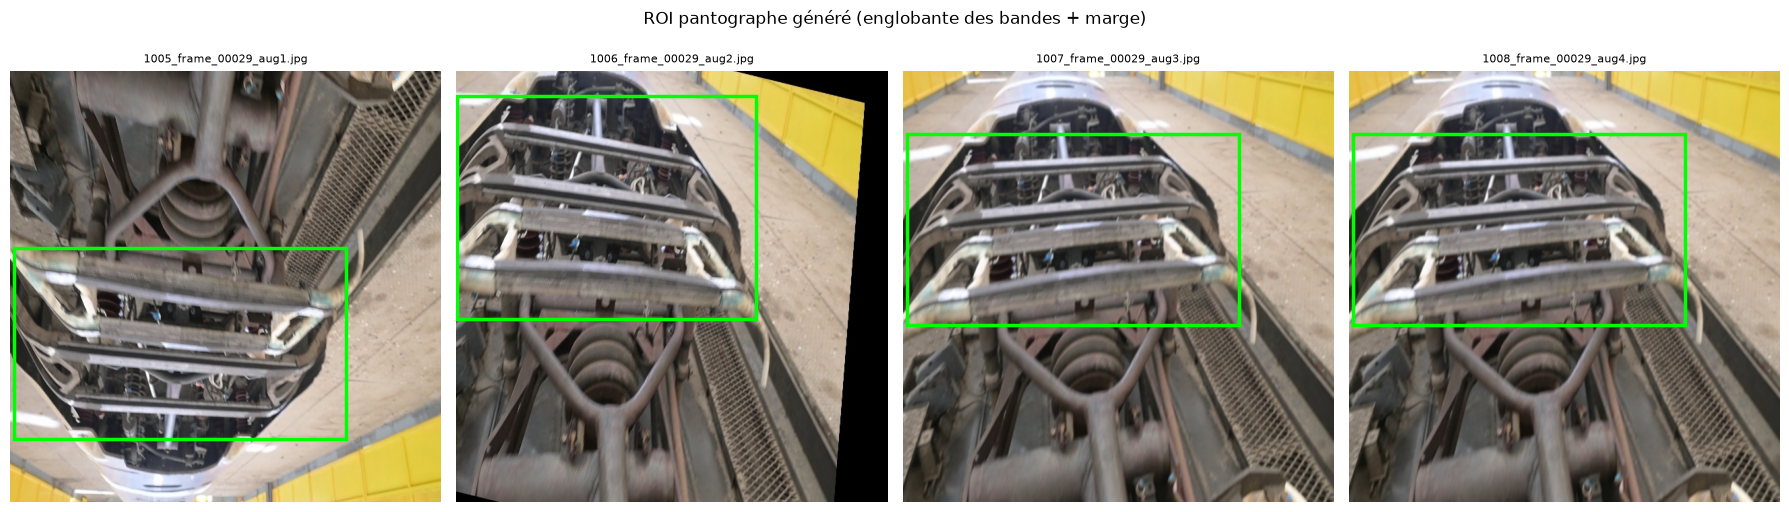

In [11]:
# ── Vérification visuelle des ROI générés ────────────────────────────────────
sample_imgs = list((Path(CFG["yolo_dataset_dir"]) / "images" / "train").glob("*.jpg"))[:4]

fig, axes = plt.subplots(1, len(sample_imgs), figsize=(18, 5))
if len(sample_imgs) == 1:
    axes = [axes]

for ax, img_path in zip(axes, sample_imgs):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl_path = Path(CFG["yolo_dataset_dir"]) / "labels" / "train" / (img_path.stem + ".txt")

    ax.imshow(img)
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                _, cx, cy, nw, nh = map(float, line.split())
                x1 = (cx - nw/2) * w
                y1 = (cy - nh/2) * h
                rect = mpatches.Rectangle((x1, y1), nw*w, nh*h,
                                           linewidth=2.5, edgecolor="lime", facecolor="none")
                ax.add_patch(rect)
    ax.set_title(img_path.name[:25], fontsize=8)
    ax.axis("off")

plt.suptitle("ROI pantographe généré (englobante des bandes + marge)", y=1.02)
plt.tight_layout()
plt.show()


COMPTAGE FICHIERS
Train images : 2996
Train labels : 2996
Val   images : 586
Val   labels : 586

Images sans label (ou inverse) : 0

DISTRIBUTION ROI (doit être < 70%)
Min    : 0.1%
Median : 54.7%
Max    : 100.0%
ROI > 70% restants : 913  ← doit être 0

APERÇU VISUEL (4 images aléatoires)


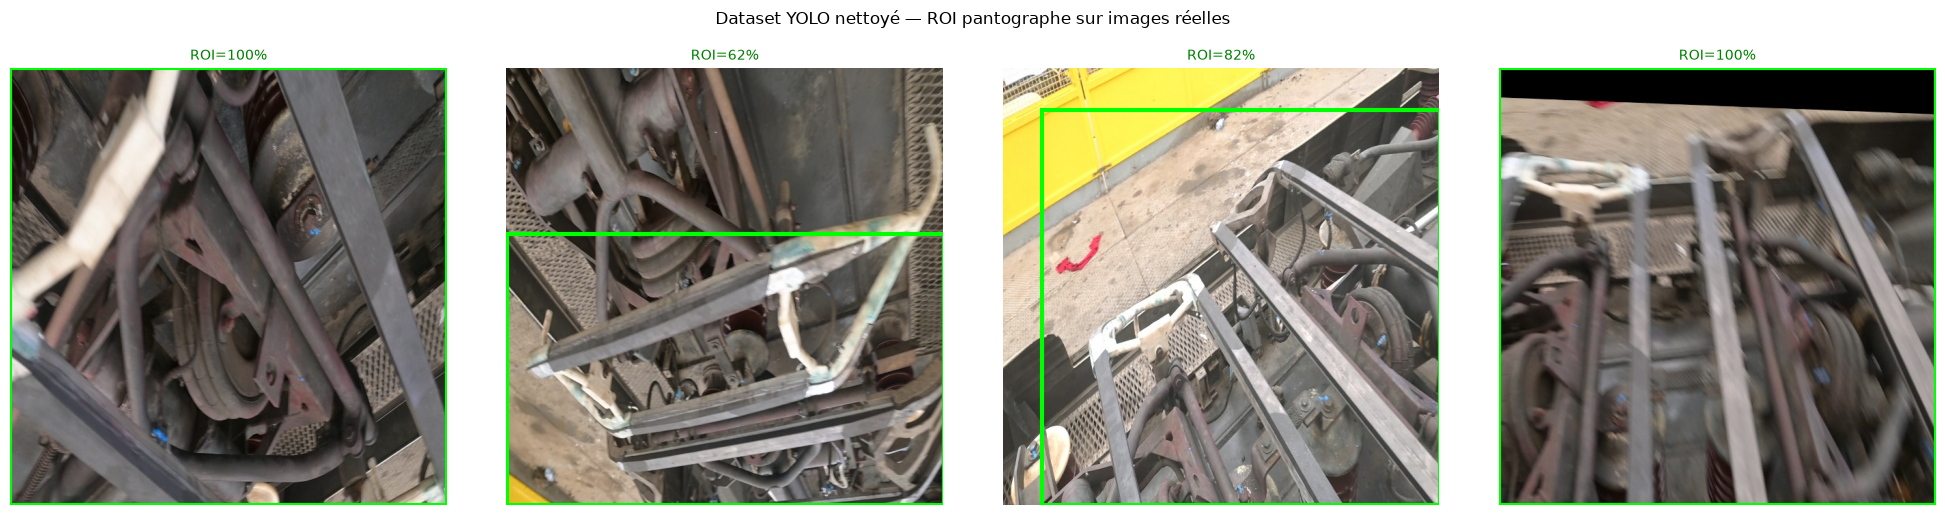


✅ Si les ROI sont bien centrés sur le pantographe → lance l'entraînement
❌ Si ROI = toute l'image → le nettoyage n'a pas tourné, relance-le d'abord


In [12]:
# ============================================================
#  VÉRIFICATION DATASET AVANT ENTRAÎNEMENT YOLO
# ============================================================

train_img_dir = Path(CFG["yolo_dataset_dir"]) / "images" / "train"
train_lbl_dir = Path(CFG["yolo_dataset_dir"]) / "labels" / "train"
val_img_dir   = Path(CFG["yolo_dataset_dir"]) / "images" / "val"
val_lbl_dir   = Path(CFG["yolo_dataset_dir"]) / "labels" / "val"

train_imgs = list(train_img_dir.glob("*.jpg"))
train_lbls = list(train_lbl_dir.glob("*.txt"))
val_imgs   = list(val_img_dir.glob("*.jpg"))
val_lbls   = list(val_lbl_dir.glob("*.txt"))

print("=" * 50)
print("COMPTAGE FICHIERS")
print("=" * 50)
print(f"Train images : {len(train_imgs)}")
print(f"Train labels : {len(train_lbls)}")
print(f"Val   images : {len(val_imgs)}")
print(f"Val   labels : {len(val_lbls)}")

# Vérifier cohérence image <-> label
train_stems_img = {p.stem for p in train_imgs}
train_stems_lbl = {p.stem for p in train_lbls}
orphans = train_stems_img.symmetric_difference(train_stems_lbl)
print(f"\nImages sans label (ou inverse) : {len(orphans)}")
if orphans:
    print(f"  Exemples : {list(orphans)[:3]}")

# Vérifier distribution ROI après nettoyage
print("\n" + "=" * 50)
print("DISTRIBUTION ROI (doit être < 70%)")
print("=" * 50)

roi_areas = []
for lbl_path in train_lbls:
    with open(lbl_path) as f:
        line = f.read().strip()
    if line:
        _, cx, cy, nw, nh = map(float, line.split())
        roi_areas.append(nw * nh * 100)

roi_areas = np.array(roi_areas)
print(f"Min    : {roi_areas.min():.1f}%")
print(f"Median : {np.median(roi_areas):.1f}%")
print(f"Max    : {roi_areas.max():.1f}%")
print(f"ROI > 70% restants : {(roi_areas > 70).sum()}  ← doit être 0")

# Aperçu visuel de 4 images avec leur ROI
print("\n" + "=" * 50)
print("APERÇU VISUEL (4 images aléatoires)")
print("=" * 50)

samples = random.sample(train_imgs, min(4, len(train_imgs)))
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, img_path in zip(axes, samples):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl_path = train_lbl_dir / (img_path.stem + ".txt")
    ax.imshow(img)
    if lbl_path.exists():
        with open(lbl_path) as f:
            _, cx, cy, nw, nh = map(float, f.read().strip().split())
        x1 = (cx - nw/2) * w
        y1 = (cy - nh/2) * h
        rect = mpatches.Rectangle((x1, y1), nw*w, nh*h,
                                   linewidth=3, edgecolor="lime", facecolor="none")
        ax.add_patch(rect)
        ax.set_title(f"ROI={nw*nh*100:.0f}%", fontsize=10, color="green")
    ax.axis("off")

plt.suptitle("Dataset YOLO nettoyé — ROI pantographe sur images réelles", y=1.02)
plt.tight_layout()
plt.show()

print("\n✅ Si les ROI sont bien centrés sur le pantographe → lance l'entraînement")
print("❌ Si ROI = toute l'image → le nettoyage n'a pas tourné, relance-le d'abord")

## Étape 3 — Entraînement YOLOv8 (détection ROI pantographe)

YOLOv8n (nano) est largement suffisant ici : une seule classe, objet macro avec forme distinctive
(structure métallique articulée), donc convergence rapide. Important pour ton usage AR temps réel :
YOLOv8n tourne facilement à 30+ FPS même sur hardware embarqué modeste.


In [25]:
# ============================================================
#  ÉTAPE 3 — ENTRAÎNEMENT YOLO
# ============================================================

from ultralytics import YOLO

yolo_model = YOLO(CFG["yolo_model"])

yolo_results = yolo_model.train(
    data       = yolo_yaml_path,
    epochs     = CFG["yolo_epochs"],
    imgsz      = CFG["yolo_imgsz"],
    batch      = CFG["yolo_batch"],
    project    = CFG["yolo_output_dir"],
    name       = "pantograph_roi",
    patience   = 20,
    device     = "cuda",
    seed       = CFG["seed"],
    degrees    = 15,
    translate  = 0.15,
    scale      = 0.6,
    shear      = 5,
    perspective= 0.0005,
    flipud     = 0.0,
    fliplr     = 0.5,
    hsv_h      = 0.02,
    hsv_s      = 0.5,
    hsv_v      = 0.4,
    mosaic     = 1.0,
    mixup      = 0.2,
    copy_paste = 0.1,
)

run_dirs = sorted(
    glob.glob(str(Path(CFG["yolo_output_dir"]) / "pantograph_roi*" / "weights" / "best.pt")),
    key=os.path.getmtime
)
if run_dirs:
    best_yolo_path = run_dirs[-1]
    print(f"✅ Meilleur modèle YOLO : {best_yolo_path}")
else:
    print("❌ Aucun best.pt trouvé")

Ultralytics 8.4.70  Python-3.11.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\oumaima.tayyarat\Documents\SegBande\yolo_pantograph\dataset.yaml, degrees=15, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.02, hsv_s=0.5, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.2, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pantograph_roi-2, nbs=64, nms=False, op

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x000002D958EA2160>
Traceback (most recent call last):
  File "c:\Users\oumaima.tayyarat\AppData\Local\anaconda3\envs\gpu_env\Lib\site-packages\torch\utils\data\dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "c:\Users\oumaima.tayyarat\AppData\Local\anaconda3\envs\gpu_env\Lib\site-packages\torch\utils\data\dataloader.py", line 1667, in _shutdown_workers
    if self._persistent_workers or self._workers_status[worker_id]:
                                   ^^^^^^^^^^^^^^^^^^^^
AttributeError: '_MultiProcessingDataLoaderIter' object has no attribute '_workers_status'


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 11.7it/s 3.2s0.1s
                   all        586        586      0.719      0.659      0.707      0.358

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      5/150      1.96G      1.371      1.412       1.85         13        640: 100% ━━━━━━━━━━━━ 300/300 18.7it/s 16.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 17.2it/s 2.2s0.1s
                   all        586        586      0.713      0.657      0.719      0.322

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      6/150      1.96G      1.352      1.399      1.836         12        640: 100% ━━━━━━━━━━━━ 300/300 18.5it/s 16.2s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 17.2it/s 2.1s0.1s
                   a

ROI couvre en moyenne : 58.9% de l'image
ROI médian            : 57.8%
ROI > 80% image       : 115 cas
ROI > 50% image       : 325 cas


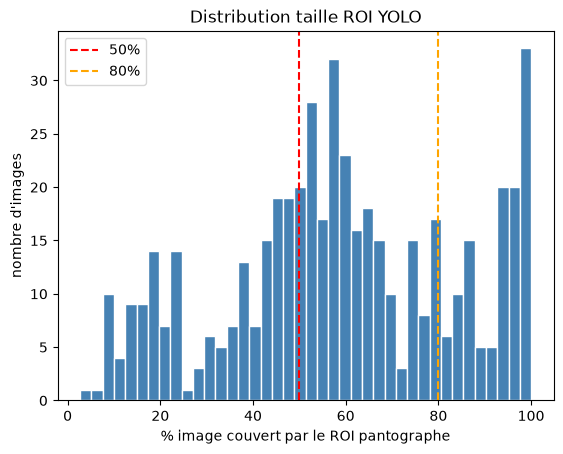

In [13]:
# ── DIAGNOSTIC : taille des ROI générés ─────────────────────
import matplotlib.pyplot as plt

roi_ratios = []
yolo_img_dir = Path(CFG["yolo_dataset_dir"]) / "images" / "train"
yolo_lbl_dir = Path(CFG["yolo_dataset_dir"]) / "labels" / "train"

for lbl_path in list(yolo_lbl_dir.glob("*.txt"))[:500]:
    with open(lbl_path) as f:
        for line in f:
            _, cx, cy, nw, nh = map(float, line.split())
            roi_ratios.append(nw * nh)  # proportion de l'image couverte

roi_ratios = np.array(roi_ratios)
print(f"ROI couvre en moyenne : {roi_ratios.mean()*100:.1f}% de l'image")
print(f"ROI médian            : {np.median(roi_ratios)*100:.1f}%")
print(f"ROI > 80% image       : {(roi_ratios > 0.8).sum()} cas")
print(f"ROI > 50% image       : {(roi_ratios > 0.5).sum()} cas")

plt.hist(roi_ratios * 100, bins=40, color="steelblue", edgecolor="white")
plt.xlabel("% image couvert par le ROI pantographe")
plt.ylabel("nombre d'images")
plt.title("Distribution taille ROI YOLO")
plt.axvline(50, color="red", linestyle="--", label="50%")
plt.axvline(80, color="orange", linestyle="--", label="80%")
plt.legend()
plt.show()

In [ ]:
# ── Métriques YOLO finales ───────────────────────────────────────────────────
best_yolo = YOLO(' met le tien du best.pt ici ')  # ✅ à modifier selon ton environnement
metrics = best_yolo.val(data=yolo_yaml_path)

print(f"\n MÉTRIQUES YOLO SUR VAL SET")
print(f"   mAP50    : {metrics.box.map50:.3f}")
print(f"   mAP50-95 : {metrics.box.map:.3f}")
print(f"   Precision: {metrics.box.mp:.3f}")
print(f"   Recall   : {metrics.box.mr:.3f}")

print("\n Si mAP50 < 0.7, vérifie :")
print("   - assez d'images avec pantographe entier visible (pas que des crops bandes lot3)")
print("   - les ROI générés à l'étape 2 sont cohérents (vérifie le plot ci-dessus)")


Ultralytics 8.4.70  Python-3.11.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 1067.0453.3 MB/s, size: 183.0 KB)
val: Scanning C:\Users\oumaima.tayyarat\Documents\SegBande\yolo_pantograph\labels\val.cache... 586 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 586/586  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 10.7it/s 3.5s0.2s
                   all        586        586      0.962      0.941      0.976      0.778
Speed: 0.9ms preprocess, 2.1ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to C:\Users\oumaima.tayyarat\Documents\SegBande\runs\detect\val-5

📊 MÉTRIQUES YOLO SUR VAL SET
   mAP50    : 0.976
   mAP50-95 : 0.778
   Precision: 0.962
   Recall   : 0.941

⚠️  Si mAP50 < 0.7, vérifie :
   - assez d'images avec pantographe entie

## Étape 4 — Génération du dataset de segmentation contraint au ROI

Maintenant qu'on a un détecteur de ROI fiable, on **recadre chaque image sur son ROI pantographe** (en utilisant
les annotations GT pour l'entraînement, pas les prédictions YOLO — c'est le ROI "vérité terrain" qui sert de
base d'entraînement à la segmentation). Les coordonnées des bandes sont ensuite recalculées dans le repère du crop.

**Effet direct sur ton problème de fond** : la zone de toiture qui ressemble aux bandes est presque toujours
hors du ROI pantographe → le modèle de segmentation la voit beaucoup moins souvent comme "contexte", donc moins
de confusion. Et les bandes occupent une bien plus grande proportion du crop → meilleure géométrie apprise
(résout le problème des boîtes quasi-carrées observé dans la V3).


In [14]:
# ============================================================
#  ÉTAPE 4 — DATASET SEGMENTATION RECADRÉ SUR ROI (depuis GT, pas prédictions)
# ============================================================

def build_roi_segmentation_dataset(merged_data, source_map, output_dir,
                                    margin_pct=0.15, target_size=640):
    """
    Pour chaque image annotée :
    1. Calcule le ROI pantographe (englobante des bandes + marge) — comme étape 2
    2. Crop l'image sur ce ROI
    3. Redimensionne à target_size x target_size
    4. Recalcule les segmentations des bandes dans le nouveau repère
    Génère un nouveau JSON COCO pour ce dataset recadré.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    img_anns = defaultdict(list)
    for ann in merged_data["annotations"]:
        img_anns[ann["image_id"]].append(ann)
    img_info_map = {img["id"]: img for img in merged_data["images"]}

    new_images, new_anns = [], []
    new_img_id, new_ann_id = 0, 0
    skipped = 0

    for img_id, anns in tqdm(img_anns.items(), desc="Recadrage ROI"):
        info = img_info_map.get(img_id)
        if info is None:
            skipped += 1
            continue
        img_dir = source_map[img_id]
        img_path = find_img_path(img_dir, info["file_name"])
        if img_path is None:
            skipped += 1
            continue
        img = cv2.imread(str(img_path))
        if img is None:
            skipped += 1
            continue

        h_img, w_img = img.shape[:2]

        xs1, ys1, xs2, ys2 = [], [], [], []
        for ann in anns:
            x, y, bw, bh = ann["bbox"]
            xs1.append(x); ys1.append(y)
            xs2.append(x + bw); ys2.append(y + bh)
        x1, y1, x2, y2 = min(xs1), min(ys1), max(xs2), max(ys2)

        roi_w, roi_h = x2 - x1, y2 - y1
        mx, my = roi_w * margin_pct, roi_h * margin_pct
        crop_x1 = int(max(0, x1 - mx)); crop_y1 = int(max(0, y1 - my))
        crop_x2 = int(min(w_img, x2 + mx)); crop_y2 = int(min(h_img, y2 + my))

        crop_w, crop_h = crop_x2 - crop_x1, crop_y2 - crop_y1
        if crop_w < 20 or crop_h < 20:
            skipped += 1
            continue

        crop_img = img[crop_y1:crop_y2, crop_x1:crop_x2]
        scale_x = target_size / crop_w
        scale_y = target_size / crop_h
        crop_img_rs = cv2.resize(crop_img, (target_size, target_size))

        out_name = f"roi_{img_id}_{Path(info['file_name']).stem}.jpg"
        cv2.imwrite(str(output_dir / out_name), crop_img_rs)

        new_images.append({
            "id": new_img_id, "file_name": out_name,
            "height": target_size, "width": target_size,
        })

        for ann in anns:
            mask = decode_segmentation(ann, h_img, w_img)
            mask_crop = mask[crop_y1:crop_y2, crop_x1:crop_x2]
            mask_rs = cv2.resize(mask_crop, (target_size, target_size),
                                  interpolation=cv2.INTER_NEAREST)

            ys, xs = np.where(mask_rs > 0)
            if len(xs) == 0:
                continue
            nx1, ny1, nx2, ny2 = int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())

            contours, _ = cv2.findContours(mask_rs, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if not contours:
                continue
            seg = max(contours, key=cv2.contourArea).flatten().tolist()
            if len(seg) < 6:
                continue

            new_anns.append({
                "id": new_ann_id, "image_id": new_img_id, "category_id": 1,
                "segmentation": [seg],
                "bbox": [nx1, ny1, nx2 - nx1, ny2 - ny1],
                "area": float(mask_rs.sum()),
                "iscrowd": 0,
            })
            new_ann_id += 1

        new_img_id += 1

    coco_out = {
        "images": new_images, "annotations": new_anns,
        "categories": [{"id": 1, "name": "contact_strip", "supercategory": ""}],
    }
    out_ann_path = output_dir.parent / "roi_segmentation_annotations.json"
    with open(out_ann_path, "w") as f:
        json.dump(coco_out, f)

    print(f"\n✅ Dataset segmentation ROI : {len(new_images)} images, {len(new_anns)} annotations")
    print(f"   Skipped : {skipped}")
    print(f"   Images  : {output_dir}")
    print(f"   Annotations : {out_ann_path}")

    return str(out_ann_path)


roi_seg_ann_path = build_roi_segmentation_dataset(
    merged_data, source_map,
    output_dir = CFG["roi_crops_dir"],
    margin_pct = CFG["roi_margin_pct"],
    target_size = 640,
)


Recadrage ROI:   0%|          | 0/2982 [00:00<?, ?it/s]

Recadrage ROI: 100%|██████████| 2982/2982 [00:51<00:00, 57.64it/s]



✅ Dataset segmentation ROI : 2982 images, 9464 annotations
   Skipped : 0
   Images  : C:\Users\oumaima.tayyarat\Documents\SegBande\roi_crops_v4
   Annotations : C:\Users\oumaima.tayyarat\Documents\SegBande\roi_segmentation_annotations.json


📊 Aspect ratio APRÈS recadrage ROI : median=2.45 (vs 2.59 avant recadrage)


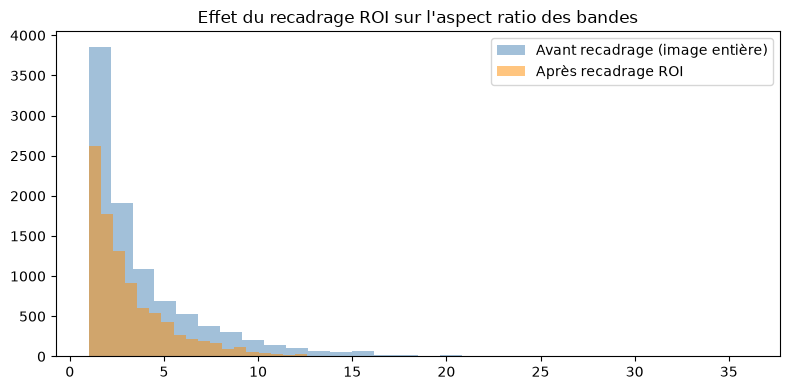

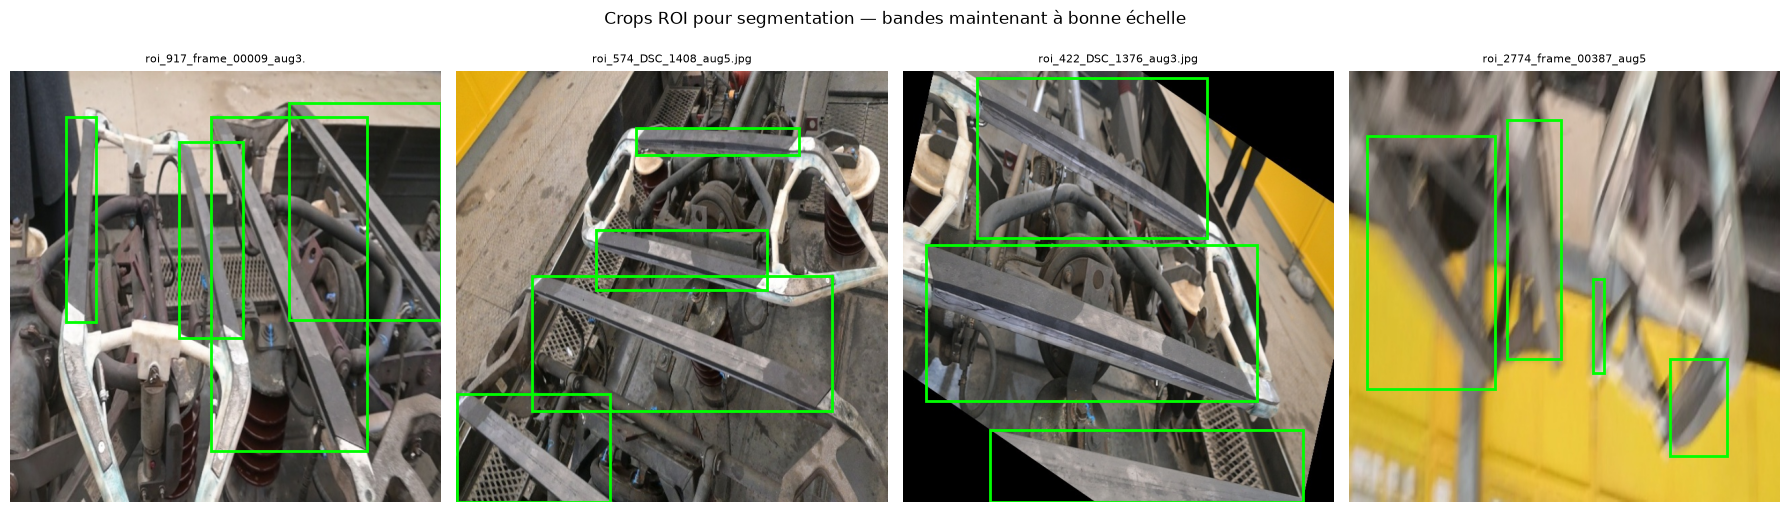

In [15]:
# ── Vérification : aspect ratio des bandes APRÈS recadrage ROI ──────────────
# Doit être nettement supérieur à avant recadrage (bandes plus grandes proportionnellement)

with open(roi_seg_ann_path) as f:
    roi_data = json.load(f)

roi_ars = []
for ann in roi_data["annotations"]:
    x, y, bw, bh = ann["bbox"]
    if bw <= 0 or bh <= 0:
        continue
    roi_ars.append(max(bw, bh) / (min(bw, bh) + 1e-6))

roi_ars = np.array(roi_ars)
print(f"📊 Aspect ratio APRÈS recadrage ROI : median={np.median(roi_ars):.2f} "
      f"(vs {np.median(aspect_ratios):.2f} avant recadrage)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(aspect_ratios, bins=30, alpha=0.5, label="Avant recadrage (image entière)", color="steelblue")
ax.hist(roi_ars, bins=30, alpha=0.5, label="Après recadrage ROI", color="darkorange")
ax.legend()
ax.set_title("Effet du recadrage ROI sur l'aspect ratio des bandes")
plt.tight_layout()
plt.show()

# ── Aperçu visuel des crops ROI avec masques ─────────────────────────────────
sample_ids = random.sample([img["id"] for img in roi_data["images"]], min(4, len(roi_data["images"])))
fig, axes = plt.subplots(1, len(sample_ids), figsize=(18, 5))
if len(sample_ids) == 1:
    axes = [axes]

ann_by_img = defaultdict(list)
for ann in roi_data["annotations"]:
    ann_by_img[ann["image_id"]].append(ann)
img_by_id = {img["id"]: img for img in roi_data["images"]}

for ax, img_id in zip(axes, sample_ids):
    info = img_by_id[img_id]
    img = cv2.cvtColor(cv2.imread(str(Path(CFG["roi_crops_dir"]) / info["file_name"])), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    for ann in ann_by_img[img_id]:
        x, y, bw, bh = ann["bbox"]
        rect = mpatches.Rectangle((x, y), bw, bh, linewidth=2, edgecolor="lime", facecolor="none")
        ax.add_patch(rect)
    ax.set_title(info["file_name"][:25], fontsize=8)
    ax.axis("off")

plt.suptitle("Crops ROI pour segmentation — bandes maintenant à bonne échelle", y=1.02)
plt.tight_layout()
plt.show()


## Étape 5 — Hard negatives (toujours nécessaires, même dans le ROI)

Même contraint au ROI pantographe, certaines zones (supports métalliques, ressorts, câbles à proximité directe
des bandes) restent visuellement proches. On garde le principe hard negatives, mais désormais extrait
**depuis les crops ROI eux-mêmes** plutôt que l'image entière — plus pertinent puisque c'est l'environnement
réel dans lequel la segmentation va opérer.


In [ ]:
# ============================================================
#  HARD NEGATIVES — extraits depuis les crops ROI (zones sans bande)
# ============================================================

def extract_background_patch(img_bgr, ann_masks, patch_size, margin_dilation=15, n_tries=50):
    h, w = img_bgr.shape[:2]
    ph, pw = patch_size
    if h <= ph or w <= pw:
        return None

    combined = np.zeros((h, w), dtype=np.uint8)
    for m in ann_masks:
        combined = np.maximum(combined, m)
    kernel = np.ones((margin_dilation, margin_dilation), np.uint8)
    forbidden = cv2.dilate(combined, kernel)
    safe = 1 - forbidden

    for _ in range(n_tries):
        y0 = random.randint(0, h - ph)
        x0 = random.randint(0, w - pw)
        if safe[y0:y0+ph, x0:x0+pw].min() == 1:
            return img_bgr[y0:y0+ph, x0:x0+pw].copy()
    return None


def generate_hard_negatives_from_roi(roi_dir, roi_ann_path, output_dir,
                                       n_images=150, patch_size=(256, 256)):
    data = load_coco_json(roi_ann_path)
    img_map = {img["id"]: img for img in data["images"]}
    ann_map = defaultdict(list)
    for ann in data["annotations"]:
        ann_map[ann["image_id"]].append(ann)

    valid_ids = [i for i in img_map if ann_map[i]]
    generated, attempts = 0, 0
    pbar = tqdm(total=n_images, desc="Hard negatives (ROI)")

    while generated < n_images and attempts < n_images * 15:
        attempts += 1
        img_id = random.choice(valid_ids)
        info = img_map[img_id]
        img_bgr = cv2.imread(str(Path(roi_dir) / info["file_name"]))
        if img_bgr is None:
            continue
        h, w = info["height"], info["width"]
        masks = [decode_segmentation(a, h, w) for a in ann_map[img_id]]
        patch = extract_background_patch(img_bgr, masks, patch_size)
        if patch is None:
            continue
        cv2.imwrite(str(Path(output_dir) / f"hardneg_{generated:04d}.jpg"), patch)
        generated += 1
        pbar.update(1)
    pbar.close()
    print(f"\n✅ Hard negatives générés : {generated}/{n_images}")
    return generated


generate_hard_negatives_from_roi(
    roi_dir      = CFG["roi_crops_dir"],
    roi_ann_path = roi_seg_ann_path,
    output_dir   = CFG["hard_neg_dir"],
    n_images     = CFG["n_hard_neg"],
    patch_size   = (256, 256),
)


Hard negatives (ROI): 100%|██████████| 150/150 [00:04<00:00, 35.20it/s]


✅ Hard negatives générés : 150/150


150

In [28]:
# ============================================================
#  AUGMENTATIONS (identiques à la V3, elles n'étaient pas le problème)
# ============================================================

def apply_visual_augmentations(img_tensor):
    img_pil = TF.to_pil_image(img_tensor)
    if random.random() > 0.3: img_pil = TF.adjust_brightness(img_pil, random.uniform(0.4, 1.8))
    if random.random() > 0.3: img_pil = TF.adjust_contrast(img_pil, random.uniform(0.4, 2.0))
    if random.random() > 0.4: img_pil = TF.adjust_saturation(img_pil, random.uniform(0.0, 2.0))
    if random.random() > 0.5: img_pil = TF.adjust_hue(img_pil, random.uniform(-0.2, 0.2))
    if random.random() > 0.4: img_pil = TF.adjust_gamma(img_pil, random.uniform(0.5, 2.0))
    img_tensor = TF.to_tensor(img_pil)
    if random.random() > 0.4:
        noise = torch.randn_like(img_tensor) * random.uniform(0.01, 0.05)
        img_tensor = torch.clamp(img_tensor + noise, 0.0, 1.0)
    if random.random() > 0.5:
        img_tensor = T.GaussianBlur(kernel_size=random.choice([3, 5]), sigma=(0.5, 1.8))(img_tensor)
    return img_tensor


def apply_geometric_augmentations(img_bgr, masks):
    h, w = img_bgr.shape[:2]
    if random.random() > 0.5:
        img_bgr = cv2.flip(img_bgr, 1)
        masks = [cv2.flip(m, 1) for m in masks]
    if random.random() > 0.5:
        angle = random.uniform(-8, 8)
        M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
        img_bgr = cv2.warpAffine(img_bgr, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
        masks = [cv2.warpAffine(m, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT) for m in masks]
    if random.random() > 0.5:
        scale = random.uniform(0.85, 1.0)
        nh, nw = int(h*scale), int(w*scale)
        y0 = random.randint(0, h-nh); x0 = random.randint(0, w-nw)
        img_bgr = cv2.resize(img_bgr[y0:y0+nh, x0:x0+nw], (w, h))
        masks = [cv2.resize(m[y0:y0+nh, x0:x0+nw], (w, h), interpolation=cv2.INTER_NEAREST) for m in masks]
    return img_bgr, masks

print("✅ Augmentations chargées")


✅ Augmentations chargées


In [16]:
# ============================================================
#  DATASET — IMAGES ROI + HARD NEGATIVES
# ============================================================

class ROISegmentationDataset(Dataset):
    def __init__(self, roi_dir, roi_ann_path, hard_neg_dir=None, is_train=True):
        self.roi_dir = Path(roi_dir)
        self.is_train = is_train

        data = load_coco_json(roi_ann_path)
        self.imgs = {img["id"]: img for img in data["images"]}
        self.ann_map = defaultdict(list)
        for ann in data["annotations"]:
            self.ann_map[ann["image_id"]].append(ann)

        self.categories = {c["id"]: c["name"] for c in data["categories"]}
        self.num_classes = len(self.categories) + 1

        self.items = []
        for img_id, info in self.imgs.items():
            if self.ann_map[img_id]:
                self.items.append((img_id, self.roi_dir / info["file_name"], "roi"))

        self.sample_weights = [1.0] * len(self.items)

        if hard_neg_dir:
            for p in sorted(Path(hard_neg_dir).glob("*.jpg")):
                self.items.append((-1, p, "hard_neg"))
                self.sample_weights.append(0.8)

        n_roi = len([x for x in self.items if x[0] != -1])
        n_hn  = len([x for x in self.items if x[0] == -1])
        print(f"📦 Dataset : {n_roi} images ROI annotées | {n_hn} hard negatives")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_id, img_path, tag = self.items[idx]
        is_hn = (img_id == -1)

        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            img_bgr = np.zeros((640, 640, 3), dtype=np.uint8)
        h, w = img_bgr.shape[:2]

        if is_hn:
            target = {
                "boxes": torch.zeros((0,4), dtype=torch.float32),
                "labels": torch.zeros((0,), dtype=torch.int64),
                "masks": torch.zeros((0,h,w), dtype=torch.uint8),
                "image_id": torch.tensor([-1]),
                "area": torch.zeros((0,), dtype=torch.float32),
                "iscrowd": torch.zeros((0,), dtype=torch.int64),
            }
        else:
            anns = self.ann_map[img_id]
            boxes, masks_list, areas = [], [], []
            for ann in anns:
                x, y, bw, bh = ann["bbox"]
                if bw < 3 or bh < 3:
                    continue
                boxes.append([x, y, x+bw, y+bh])
                areas.append(ann.get("area", bw*bh))
                masks_list.append(decode_segmentation(ann, h, w))

            if self.is_train and masks_list and random.random() > 0.4:
                img_bgr, masks_list = apply_geometric_augmentations(img_bgr, masks_list)
                boxes, areas = [], []
                for m in masks_list:
                    ys, xs = np.where(m > 0)
                    if len(xs) == 0:
                        continue
                    x1, y1, x2, y2 = int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())
                    boxes.append([x1, y1, x2, y2])
                    areas.append(float((x2-x1)*(y2-y1)))

            if not boxes:
                target = {
                    "boxes": torch.zeros((0,4), dtype=torch.float32),
                    "labels": torch.zeros((0,), dtype=torch.int64),
                    "masks": torch.zeros((0,h,w), dtype=torch.uint8),
                    "image_id": torch.tensor([img_id]),
                    "area": torch.zeros((0,), dtype=torch.float32),
                    "iscrowd": torch.zeros((0,), dtype=torch.int64),
                }
            else:
                target = {
                    "boxes": torch.as_tensor(boxes, dtype=torch.float32),
                    "labels": torch.as_tensor([1]*len(boxes), dtype=torch.int64),
                    "masks": torch.as_tensor(np.stack(masks_list), dtype=torch.uint8),
                    "image_id": torch.tensor([img_id]),
                    "area": torch.as_tensor(areas, dtype=torch.float32),
                    "iscrowd": torch.zeros(len(boxes), dtype=torch.int64),
                }

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_tensor = torch.from_numpy(img_rgb).permute(2,0,1).float() / 255.0
        if self.is_train:
            img_tensor = apply_visual_augmentations(img_tensor)

        return img_tensor, target


def collate_fn(batch):
    return tuple(zip(*batch))


def split_no_leakage(dataset, train_ratio=0.8, seed=42):
    groups = defaultdict(list)
    for i, (img_id, img_path, tag) in enumerate(dataset.items):
        base = re.sub(r"_(aug|cp_v[0-9]?)\d+$", "", Path(img_path).stem)
        groups[base].append(i)
    keys = list(groups.keys())
    random.seed(seed); random.shuffle(keys)
    split = int(len(keys) * train_ratio)
    train_idx = [i for g in keys[:split] for i in groups[g]]
    val_idx   = [i for g in keys[split:] for i in groups[g]]
    print(f"📂 Split : {len(keys)} groupes — train={len(train_idx)} | val={len(val_idx)}")
    return Subset(dataset, train_idx), Subset(dataset, val_idx)

print("✅ Dataset ROI défini")


✅ Dataset ROI défini


In [ ]:
# ============================================================
#  MODÈLE MASK R-CNN — entraîné UNIQUEMENT sur les crops ROI
# ============================================================

def get_model(num_classes, pretrained_ckpt=None):
    model = maskrcnn_resnet50_fpn(weights="DEFAULT")
    in_feat = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_feat, num_classes)
    in_feat_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_feat_mask, 256, num_classes)

    if pretrained_ckpt and Path(pretrained_ckpt).exists():
        ckpt = torch.load(pretrained_ckpt, map_location="cpu")
        state = ckpt.get("model_state_dict", ckpt)
        missing, unexpected = model.load_state_dict(state, strict=False)
        print(f"📥 Checkpoint chargé — missing={len(missing)} unexpected={len(unexpected)}")
    else:
        print("🆕 Entraînement from scratch (poids COCO ImageNet)")
    return model


def train_one_epoch(model, optimizer, loader, device, epoch, n_epochs):
    model.train()
    total, n = 0.0, 0
    for i, (images, targets) in enumerate(loader):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        valid_idx = [j for j, t in enumerate(targets) if len(t["boxes"]) > 0]
        if not valid_idx:
            continue
        images_v = [images[j] for j in valid_idx]
        targets_v = [targets[j] for j in valid_idx]
        try:
            loss_dict = model(images_v, targets_v)
        except Exception as e:
            print(f"  ⚠️ batch {i} erreur: {e}")
            continue
        losses = sum(loss_dict.values())
        optimizer.zero_grad()
        losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        total += losses.item(); n += 1
        if i % 50 == 0:
            print(f"  Epoch [{epoch+1}/{n_epochs}] Step [{i}/{len(loader)}] Loss: {losses.item():.4f}")
    return total / max(n, 1)


@torch.no_grad()
def evaluate(model, loader, device):
    model.train()
    total, n = 0.0, 0
    for images, targets in loader:
        valid = [j for j, t in enumerate(targets) if len(t["boxes"]) > 0]
        if not valid:
            continue
        images_v = [images[j].to(device) for j in valid]
        targets_v = [{k: v.to(device) for k, v in targets[j].items()} for j in valid]
        try:
            loss_dict = model(images_v, targets_v)
            total += sum(loss_dict.values()).item(); n += 1
        except Exception:
            pass
    return total / max(n, 1)


def train_segmentation(cfg, roi_dir, roi_ann_path, hard_neg_dir):
    device = torch.device(cfg["device"])

    full_ds = ROISegmentationDataset(roi_dir, roi_ann_path, hard_neg_dir, is_train=True)
    train_sub, val_sub = split_no_leakage(full_ds, train_ratio=0.8)

    val_ds_clean = ROISegmentationDataset(roi_dir, roi_ann_path, None, is_train=False)
    _, val_clean = split_no_leakage(val_ds_clean, train_ratio=0.8)

    weights = [full_ds.sample_weights[i] for i in train_sub.indices]
    sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

    train_loader = DataLoader(train_sub, batch_size=cfg["batch_size"], sampler=sampler,
                               num_workers=0, collate_fn=collate_fn, pin_memory=True)
    val_loader = DataLoader(val_clean, batch_size=cfg["batch_size"], shuffle=False,
                             num_workers=0, collate_fn=collate_fn, pin_memory=True)

    print(f"\nTrain batches: {len(train_loader)} | Val batches: {len(val_loader)}")

    model = get_model(full_ds.num_classes, cfg.get("pretrained_ckpt"))
    model.to(device)

    lr = cfg["lr_finetune"] if cfg.get("pretrained_ckpt") else cfg["lr_from_scratch"]
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.SGD(params, lr=lr, momentum=0.9, weight_decay=cfg["weight_decay"])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["num_epochs"], eta_min=1e-5)

    best_val, patience_ctr = float("inf"), 0
    history = {"train": [], "val": []}

    for epoch in range(cfg["num_epochs"]):
        print(f"\n📅 Epoch {epoch+1}/{cfg['num_epochs']}  LR={optimizer.param_groups[0]['lr']:.6f}")
        train_loss = train_one_epoch(model, optimizer, train_loader, device, epoch, cfg["num_epochs"])
        val_loss = evaluate(model, val_loader, device)
        scheduler.step()

        history["train"].append(train_loss); history["val"].append(val_loss)
        print(f"📊 train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

        if val_loss < best_val:
            best_val, patience_ctr = val_loss, 0
            torch.save({
                "epoch": epoch, "model_state_dict": model.state_dict(),
                "val_loss": val_loss, "train_loss": train_loss,
                "num_classes": full_ds.num_classes, "categories": full_ds.categories,
            }, os.path.join(cfg["seg_output_dir"], "best_model_v4_roi.pth"))
            print(f"✅ Meilleur modèle sauvegardé (val_loss={val_loss:.4f})")
        else:
            patience_ctr += 1
            print(f"⏳ Patience {patience_ctr}/{cfg['patience']}")
            if patience_ctr >= cfg["patience"]:
                print(f"🛑 Early stopping epoch {epoch+1}")
                break

    plt.figure(figsize=(10,4))
    plt.plot(history["train"], label="train"); plt.plot(history["val"], label="val")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
    plt.title("Mask R-CNN V4 — entraînement sur crops ROI")
    plt.savefig(os.path.join(cfg["seg_output_dir"], "loss_curve_v4.png"), dpi=120)
    plt.show()

    return model


seg_model = train_segmentation(
    CFG,
    roi_dir      = CFG["roi_crops_dir"],
    roi_ann_path = roi_seg_ann_path,
    hard_neg_dir = CFG["hard_neg_dir"],
)


In [21]:
# ============================================================
#  POST-PROCESSING — seuils CALIBRÉS sur tes vraies données (étape 1)
#  Filet de sécurité, pas la solution principale cette fois.
# ============================================================

def filter_predictions_geometric(preds, score_thresh, min_aspect_ratio,
                                   min_area, max_area, nms_iou_thresh=0.4):
    boxes = preds["boxes"].cpu(); scores = preds["scores"].cpu()
    masks = preds["masks"].cpu(); labels = preds["labels"].cpu()

    keep = []
    for i in range(len(scores)):
        if scores[i].item() < score_thresh:
            continue
        x1,y1,x2,y2 = boxes[i].tolist()
        w, h = x2-x1, y2-y1
        area = w*h
        ar = max(w,h) / (min(w,h) + 1e-6)
        if ar < min_aspect_ratio:
            continue
        if not (min_area <= area <= max_area):
            continue
        keep.append(i)

    if not keep:
        return {"boxes": torch.zeros((0,4)), "scores": torch.zeros((0,)),
                "masks": torch.zeros((0,1,*masks.shape[2:])), "labels": torch.zeros((0,), dtype=torch.int64)}

    keep_t = torch.tensor(keep)
    nms_keep = ops.nms(boxes[keep_t], scores[keep_t], nms_iou_thresh)
    final = keep_t[nms_keep]
    return {"boxes": boxes[final], "scores": scores[final],
            "masks": masks[final], "labels": labels[final]}


print("✅ Post-processing défini avec seuils calibrés :")
print(f"   min_aspect_ratio = {CFG['min_aspect_ratio']:.2f}  (mesuré, pas deviné)")
print(f"   min_area         = {CFG['min_area']:.0f}")
print(f"   max_area         = {CFG['max_area']:.0f}")


✅ Post-processing défini avec seuils calibrés :
   min_aspect_ratio = 0.82  (mesuré, pas deviné)
   min_area         = 561
   max_area         = 1652737


## Étape 6 — Pipeline d'inférence complet (YOLO → crop → segmentation → filtre)

C'est ce pipeline qui tourne en production sur le flux caméra du casque AR.


In [22]:
# ============================================================
#  PIPELINE D'INFÉRENCE COMPLET
# ============================================================

def load_seg_model(ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device)
    n_cls = ckpt.get("num_classes", 2)
    model = get_model(n_cls)
    model.load_state_dict(ckpt["model_state_dict"])
    model.to(device); model.eval()
    print(f"✅ Modèle segmentation chargé — epoch {ckpt.get('epoch',0)+1} | val_loss={ckpt.get('val_loss',0):.4f}")
    return model


def full_pipeline_inference(img_bgr, yolo_model, seg_model, device, cfg, margin_pct=0.15):
    """
    1. YOLO détecte le ROI pantographe
    2. Crop l'image sur ce ROI (avec marge)
    3. Segmentation Mask R-CNN sur le crop
    4. Filtre géométrique calibré
    5. Reprojection des masques/boxes dans le repère original

    Retourne : dict avec roi_box, et liste de détections (box, mask, score) en coordonnées ORIGINALES.
    """
    h_orig, w_orig = img_bgr.shape[:2]

    # ── 1. Détection ROI ──────────────────────────────────────────────────────
    yolo_res = yolo_model.predict(img_bgr, conf=cfg["yolo_conf_thresh"], verbose=False)[0]
    if len(yolo_res.boxes) == 0:
        return {"roi_box": None, "detections": [], "status": "no_pantograph_detected"}

    # Prendre la détection avec le meilleur score
    best_idx = yolo_res.boxes.conf.argmax().item()
    rx1, ry1, rx2, ry2 = yolo_res.boxes.xyxy[best_idx].cpu().numpy()

    # Marge additionnelle
    rw, rh = rx2-rx1, ry2-ry1
    mx, my = rw*margin_pct, rh*margin_pct
    rx1 = max(0, rx1-mx); ry1 = max(0, ry1-my)
    rx2 = min(w_orig, rx2+mx); ry2 = min(h_orig, ry2+my)
    rx1, ry1, rx2, ry2 = int(rx1), int(ry1), int(rx2), int(ry2)

    # ── 2. Crop + resize ──────────────────────────────────────────────────────
    crop = img_bgr[ry1:ry2, rx1:rx2]
    crop_h, crop_w = crop.shape[:2]
    target = 640
    crop_rs = cv2.resize(crop, (target, target))
    scale_x = crop_w / target
    scale_y = crop_h / target

    # ── 3. Segmentation sur le crop ──────────────────────────────────────────
    img_tensor = torch.from_numpy(cv2.cvtColor(crop_rs, cv2.COLOR_BGR2RGB)).permute(2,0,1).float()/255.0
    with torch.no_grad():
        raw_preds = seg_model([img_tensor.to(device)])[0]

    # ── 4. Filtre géométrique calibré ────────────────────────────────────────
    filtered = filter_predictions_geometric(
        raw_preds,
        score_thresh      = cfg["score_thresh"] if "score_thresh" in cfg else 0.5,
        min_aspect_ratio   = cfg["min_aspect_ratio"],
        min_area           = cfg["min_area"] / (scale_x*scale_y),  # ajuster l'échelle
        max_area           = cfg["max_area"] / (scale_x*scale_y),
        nms_iou_thresh      = 0.4,
    )

    # ── 5. Reprojection dans le repère original ──────────────────────────────
    detections = []
    for i in range(len(filtered["boxes"])):
        bx1, by1, bx2, by2 = filtered["boxes"][i].tolist()
        orig_box = [
            rx1 + bx1*scale_x, ry1 + by1*scale_y,
            rx1 + bx2*scale_x, ry1 + by2*scale_y,
        ]
        mask_crop = filtered["masks"][i,0].numpy() > 0.5
        mask_full = np.zeros((h_orig, w_orig), dtype=np.uint8)
        mask_resized_to_crop = cv2.resize(mask_crop.astype(np.uint8), (crop_w, crop_h),
                                           interpolation=cv2.INTER_NEAREST)
        mask_full[ry1:ry2, rx1:rx2] = mask_resized_to_crop

        detections.append({
            "box": orig_box,
            "mask": mask_full,
            "score": filtered["scores"][i].item(),
        })

    return {"roi_box": [rx1, ry1, rx2, ry2], "detections": detections, "status": "ok"}


print("✅ Pipeline d'inférence complet défini")


✅ Pipeline d'inférence complet défini
